# Red Wine Quality QC

**ML Zoomcamp 2026 — midterm project**

Predict, from a batch's lab analysis, the probability that the sensory panel will rate a red *Vinho Verde* wine as **good** (quality ≥ 7).

Contents:
1. Problem description
2. Data loading and preparation
3. Exploratory data analysis (EDA)
4. Validation framework
5. Baselines
6. Logistic regression
7. Decision tree
8. Random forest
9. XGBoost
10. Model comparison and feature importance
11. Threshold selection
12. Final model and test evaluation
13. Summary

## 1. Problem description

**Context.** Before bottling, a winery's lab measures the physicochemical profile of each batch: acidity, sugar, sulfur dioxide, sulphates, alcohol and so on. The final quality grade comes from a sensory panel of trained tasters, which is slow and expensive.

**Problem.** Given the 11 lab values of a red Vinho Verde batch, estimate the probability that the panel will rate it **good** (quality ≥ 7 on a 0–10 scale). This is a **binary classification** problem.

**How the model is used.** A QC technician sends the lab values to a REST API and gets back `good_probability` and a yes/no flag. The winery uses this to:
- (a) prioritise which batches go to the full tasting panel or the premium line;
- (b) flag likely-mediocre batches early, while blending or adjustments are still possible.

**Who it is *not* for.** Consumers in a shop. They don't know a wine's volatile acidity or sulphates.

**Metric.** Only ~13.5% of wines are good, so the classes are imbalanced and **accuracy is misleading**: a model that always answers "not good" is already ~86% accurate. Instead:
- primary metric: **ROC AUC** (does not depend on a threshold);
- secondary metric: **PR AUC** (average precision), which focuses on the rare positive class.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, train_test_split

%matplotlib inline
pd.set_option('display.max_columns', 20)
sns.set_theme(style='whitegrid')

def save(name):
    # save the current figure for the README
    plt.savefig(f'images/{name}.png', dpi=110, bbox_inches='tight')

## 2. Data loading and preparation

The dataset is the UCI *Wine Quality* data (Cortez et al., 2009), red wines only. The UCI file is separated by semicolons, while some copies elsewhere (e.g. Kaggle) use commas. `sep=None, engine='python'` lets pandas detect the separator, so either version works.

In [2]:
df = pd.read_csv('data/winequality-red.csv', sep=None, engine='python')
df.columns = df.columns.str.lower().str.replace(' ', '_')
df.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
df.dtypes

fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
ph                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

In [4]:
print('shape:', df.shape)
df.isnull().sum()

shape: (1599, 12)


fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
ph                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

All 12 columns are numeric (11 lab measurements plus the `quality` score), and there are **no missing values**, so no imputation is needed.

### 2.1 Duplicates

Each row should be a different wine sample. Let's check for rows that are exact copies of each other.

In [5]:
n_dup = df.duplicated().sum()
print(f'exact duplicate rows: {n_dup} ({n_dup / len(df):.1%})')
print(f'unique rows: {len(df.drop_duplicates())}')

exact duplicate rows: 240 (15.0%)
unique rows: 1359


In [6]:
# a few examples: every row that has at least one identical copy, sorted so copies sit together
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6)

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality
142,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.9916,3.68,0.79,14.0,6
144,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.9916,3.68,0.79,14.0,6
131,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.9937,3.63,0.63,13.0,5
132,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.9937,3.63,0.63,13.0,5
1488,5.6,0.54,0.04,1.7,0.049,5.0,13.0,0.9942,3.72,0.58,11.4,5
1491,5.6,0.54,0.04,1.7,0.049,5.0,13.0,0.9942,3.72,0.58,11.4,5


#### Why duplicates matter: leakage

If an identical row lands in both the training part and the validation part of a split, the model is validated partly on rows it has already seen. The score then looks better than it would on genuinely new batches.

To measure the effect, we run the same experiment twice, once on the raw data and once on the de-duplicated data. The experiment is a default random forest with stratified 5-fold cross-validation, repeated 3 times with different shuffles so the comparison isn't down to one lucky split.

*(The target `good` is defined properly in §2.2; here we only need it for the experiment.)*

In [7]:
features = [c for c in df.columns if c != 'quality']

def cv_auc(data):
    X = data[features]
    y = (data.quality >= 7).astype(int)
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1)
    rf = RandomForestClassifier(random_state=1, n_jobs=-1)
    return cross_val_score(rf, X, y, cv=cv, scoring='roc_auc')

for name, data in [('raw (with duplicates)', df), ('de-duplicated', df.drop_duplicates())]:
    scores = cv_auc(data)
    print(f'{name:22s} ROC AUC = {scores.mean():.3f} ± {scores.std():.3f}')

raw (with duplicates)  ROC AUC = 0.917 ± 0.036


de-duplicated          ROC AUC = 0.872 ± 0.033


In [8]:
# How often does a validation row have an identical copy in training? (one 5-fold split on the raw data)
from sklearn.model_selection import StratifiedKFold

y_raw = (df.quality >= 7).astype(int)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
shares = []
for tr_idx, va_idx in skf.split(df, y_raw):
    train_rows = set(map(tuple, df.iloc[tr_idx].values))
    seen = [tuple(r) in train_rows for r in df.iloc[va_idx].values]
    shares.append(np.mean(seen))
print(f'validation rows that also appear in training: {np.mean(shares):.1%} on average')

validation rows that also appear in training: 23.4% on average


**Decision:** drop duplicates **before** any splitting. Doing it after the split would be too late, because the copies would already be on both sides.

In [9]:
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(1359, 12)

### 2.2 Target

`good = 1` if `quality >= 7`, otherwise 0. We keep `quality` only for EDA (it explains *why* a wine is good); it is **never** used as a model feature, because it *is* the answer.

In [10]:
df['good'] = (df.quality >= 7).astype(int)
df[['quality', 'good']].value_counts().sort_index()

quality  good
3        0        10
4        0        53
5        0       577
6        0       535
7        1       167
8        1        17
Name: count, dtype: int64

> **Takeaway (§2).** The data is clean (no missing values, all numeric) but has 240 exact duplicates (15%). About a quarter of validation rows had an identical copy in training, which inflated the cross-validated random-forest AUC by roughly 0.045 (0.917 vs 0.872). That gap is bigger than the fold-to-fold spread. We drop them before splitting and keep 1,359 unique wines.

## 3. Exploratory data analysis

### 3.1 Ranges of values

In [11]:
df[features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed_acidity,1359.0,8.311,1.737,4.600,7.100,7.900,9.200,15.900
volatile_acidity,1359.0,0.529,0.183,0.120,0.390,0.520,0.640,1.580
citric_acid,1359.0,0.272,0.196,0.000,0.090,0.260,0.430,1.000
residual_sugar,1359.0,2.523,1.352,0.900,1.900,2.200,2.600,15.500
chlorides,1359.0,0.088,0.049,0.012,0.070,0.079,0.091,0.611
free_sulfur_dioxide,1359.0,15.893,10.447,1.000,7.000,14.000,21.000,72.000
total_sulfur_dioxide,1359.0,46.826,33.409,6.000,22.000,38.000,63.000,289.000
density,1359.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
ph,1359.0,3.310,0.155,2.740,3.210,3.310,3.400,4.010
sulphates,1359.0,0.659,0.171,0.330,0.550,0.620,0.730,2.000


Most features have a maximum far above the 75th percentile, for example `total_sulfur_dioxide`, `chlorides`, `residual_sugar` and `sulphates`. These are long right tails, which we look at in §3.3 and §3.6. All values are physically plausible: there are no negative concentrations, pH is between ~2.7 and ~4, and density is close to that of water.

### 3.2 Target analysis

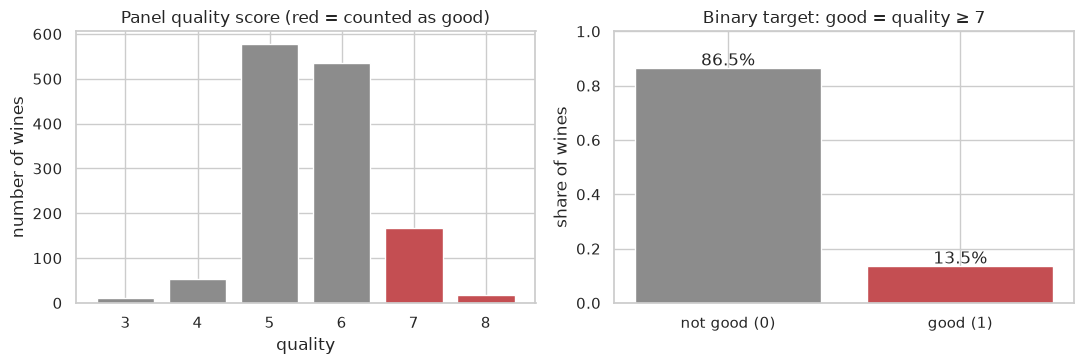

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

counts = df.quality.value_counts().sort_index()
colors = ['#c44e52' if q >= 7 else '#8c8c8c' for q in counts.index]
axes[0].bar(counts.index.astype(str), counts.values, color=colors)
axes[0].set_title('Panel quality score (red = counted as good)')
axes[0].set_xlabel('quality'); axes[0].set_ylabel('number of wines')

share = df.good.value_counts(normalize=True).sort_index()
axes[1].bar(['not good (0)', 'good (1)'], share.values, color=['#8c8c8c', '#c44e52'])
for i, v in enumerate(share.values):
    axes[1].text(i, v + 0.01, f'{v:.1%}', ha='center')
axes[1].set_title('Binary target: good = quality ≥ 7')
axes[1].set_ylabel('share of wines'); axes[1].set_ylim(0, 1)

plt.tight_layout()
save('target_distribution')
plt.show()

In [13]:
print(df.quality.value_counts().sort_index().to_dict())
print(f'share of good wines: {df.good.mean():.3f}')
print(f'accuracy of always predicting "not good": {1 - df.good.mean():.3f}')

{3: 10, 4: 53, 5: 577, 6: 535, 7: 167, 8: 17}
share of good wines: 0.135
accuracy of always predicting "not good": 0.865


Most wines score 5 or 6, and very few reach the extremes (3 or 8). Only about 13.5% are good, so a useless model that always says "not good" already scores ~86.5% accuracy. This is why we evaluate with ROC AUC and PR AUC rather than accuracy, and why every split below is **stratified** (it keeps the 13.5% share in every part).

### 3.3 Feature distributions by class

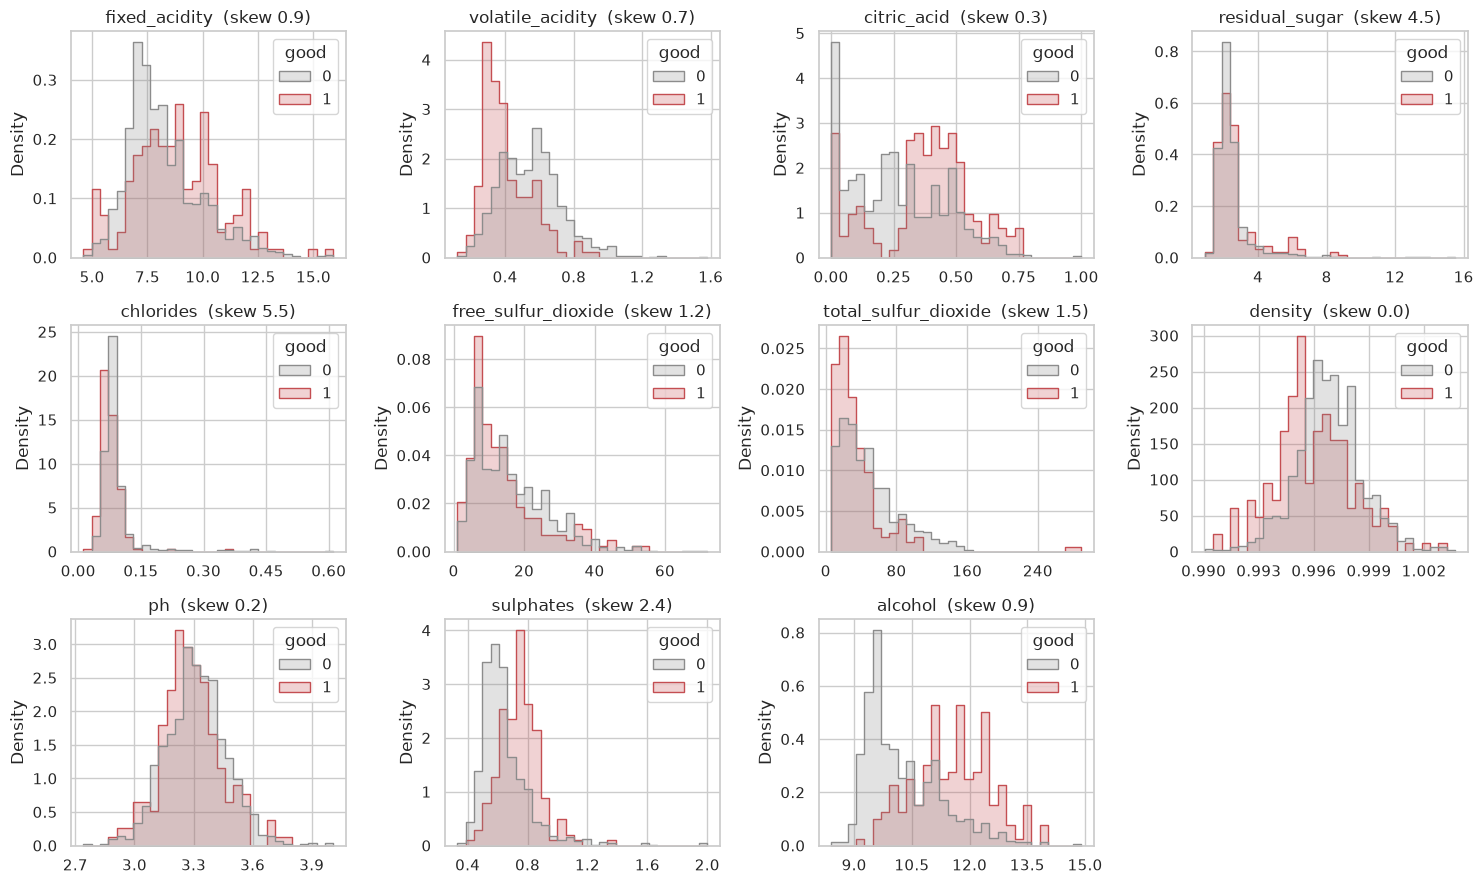

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, col in zip(axes.flat, features):
    sns.histplot(data=df, x=col, hue='good', stat='density', common_norm=False,
                 element='step', bins=30, ax=ax, palette=['#8c8c8c', '#c44e52'])
    ax.set_title(f'{col}  (skew {df[col].skew():.1f})')
    ax.set_xlabel('')
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
axes.flat[-1].axis('off')
plt.tight_layout()
save('feature_distributions')
plt.show()

In [15]:
df[features].skew().sort_values(ascending=False).round(2)

chlorides               5.50
residual_sugar          4.55
sulphates               2.41
total_sulfur_dioxide    1.54
free_sulfur_dioxide     1.23
fixed_acidity           0.94
alcohol                 0.86
volatile_acidity        0.73
citric_acid             0.31
ph                      0.23
density                 0.04
dtype: float64

Each class is normalised separately (`common_norm=False`), so we compare *shapes*, not counts.

- **Strongly right-skewed:** `chlorides`, `residual_sugar`, `sulphates`, `total_sulfur_dioxide` and `free_sulfur_dioxide`. Most wines sit in a narrow band, with a long tail of extreme values. A linear model may benefit from `log1p` on these (we test that in §6). Tree models don't care, because they only use the order of values.
- **Visibly shifted between classes:** `alcohol` (good wines have more), `volatile_acidity` (good wines have less), plus `sulphates` and `citric_acid` (good wines have more).
- **Nearly identical for both classes:** `residual_sugar`, `ph` and `free_sulfur_dioxide`, so expect little signal from them.

### 3.4 Top features vs quality

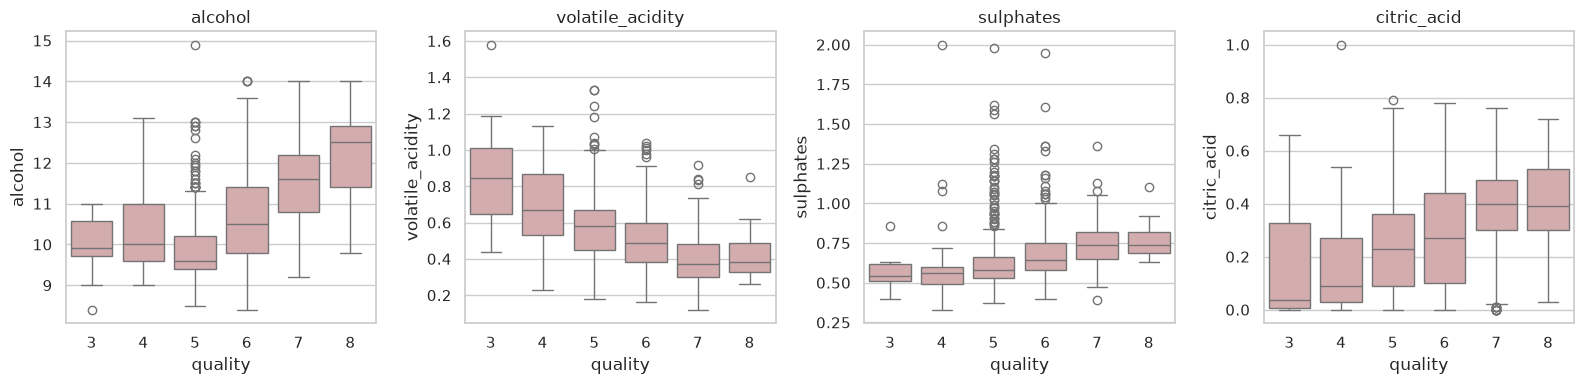

In [16]:
top = ['alcohol', 'volatile_acidity', 'sulphates', 'citric_acid']
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, top):
    sns.boxplot(data=df, x='quality', y=col, ax=ax, color='#d9a5a7')
    ax.set_title(col)
plt.tight_layout()
save('top_features_boxplots')
plt.show()

In [17]:
df.groupby('good')[top].median()

,alcohol,volatile_acidity,sulphates,citric_acid
good,,,,
0,10.0,0.54,0.60,0.24
1,11.6,0.37,0.74,0.40


The trends run across the whole scale, not just at the 7 cut-off. Median alcohol rises with quality, volatile acidity (vinegar-like acetic acid, a known fault) falls, and sulphates and citric acid rise. The boxes overlap a lot, though, so no single feature separates good from not-good wines by itself, and a model that combines them should help.

### 3.5 Correlation

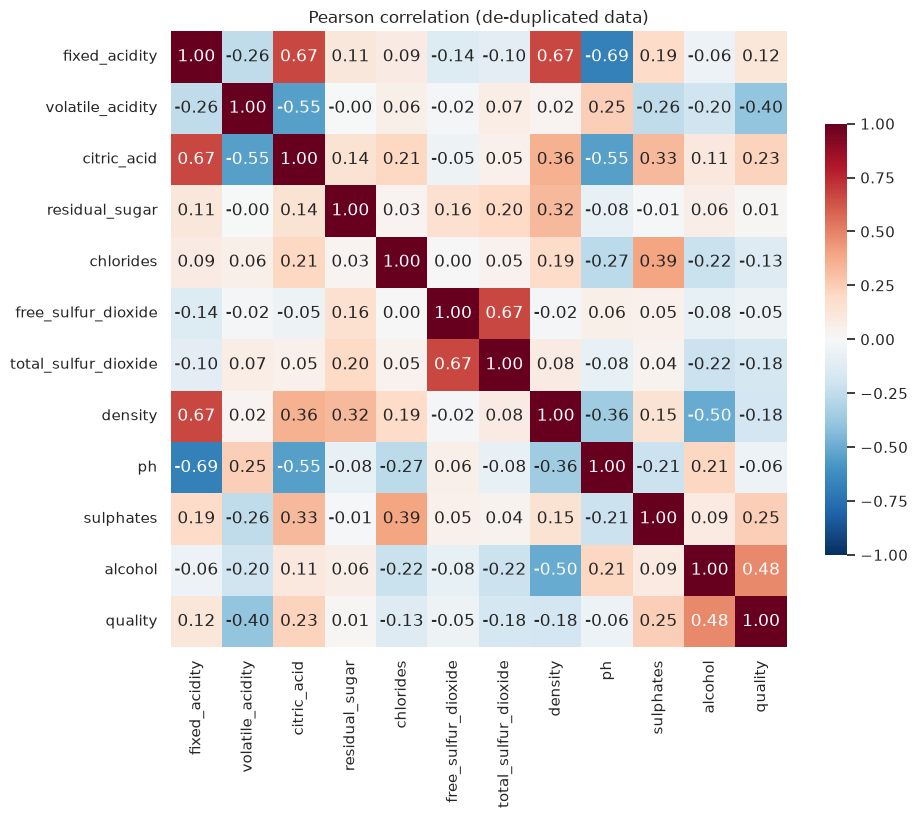

In [18]:
corr = df[features + ['quality']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True,
            cbar_kws={'shrink': 0.7})
plt.title('Pearson correlation (de-duplicated data)')
save('correlation_heatmap')
plt.show()

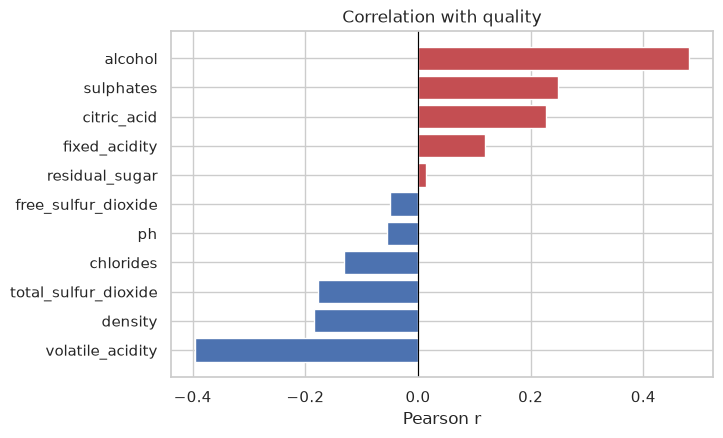

alcohol                 0.480
volatile_acidity       -0.395
sulphates               0.249
citric_acid             0.228
density                -0.184
total_sulfur_dioxide   -0.178
chlorides              -0.131
fixed_acidity           0.119
ph                     -0.055
free_sulfur_dioxide    -0.050
residual_sugar          0.014
Name: quality, dtype: float64

In [19]:
corr_q = corr['quality'].drop('quality').sort_values()

plt.figure(figsize=(7, 4.5))
plt.barh(corr_q.index, corr_q.values, color=['#c44e52' if v > 0 else '#4c72b0' for v in corr_q.values])
plt.axvline(0, color='black', lw=0.8)
plt.title('Correlation with quality')
plt.xlabel('Pearson r')
save('correlation_with_quality')
plt.show()

corr_q.sort_values(key=abs, ascending=False).round(3)

In [20]:
# collinear feature pairs (|r| > 0.5)
pairs = (corr.loc[features, features]
         .where(np.triu(np.ones((len(features), len(features)), dtype=bool), k=1))
         .stack()
         .rename('r'))
pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False).round(2)

fixed_acidity        ph                     -0.69
                     density                 0.67
                     citric_acid             0.67
free_sulfur_dioxide  total_sulfur_dioxide    0.67
volatile_acidity     citric_acid            -0.55
citric_acid          ph                     -0.55
density              alcohol                -0.50
Name: r, dtype: float64

- **Strongest linear relations with quality:** `alcohol` (positive) and `volatile_acidity` (negative), followed by `sulphates` and `citric_acid` (positive).
- **Collinear groups:**
  - the "acidity block": `fixed_acidity`, `citric_acid`, `density` and `ph` (more acid means lower pH);
  - `free_sulfur_dioxide` with `total_sulfur_dioxide` (the free part is included in the total);
  - `density` with `alcohol` (alcohol is lighter than water).

  Collinearity doesn't hurt predictions much, but it makes **logistic regression coefficients harder to interpret**: correlated features share credit. Regularisation (the `C` parameter) keeps them stable.

### 3.6 Mutual information with the target

Correlation only captures *linear* relations. **Mutual information** (MI) measures how much knowing a feature reduces uncertainty about `good`, including non-linear relations. 0 means the feature tells us nothing about the target.

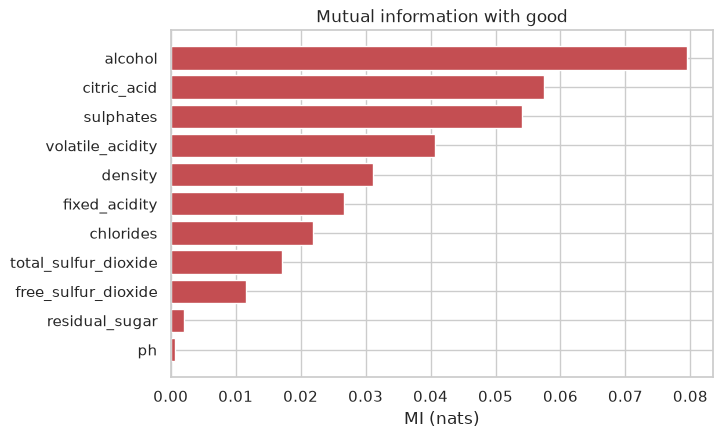

,mi,mi_rank,abs_corr_with_good,corr_rank
alcohol,0.0795,1,0.410,1
citric_acid,0.0574,2,0.204,3
sulphates,0.0541,3,0.202,4
volatile_acidity,0.0406,4,0.267,2
density,0.0311,5,0.158,5
fixed_acidity,0.0266,6,0.116,7
chlorides,0.0219,7,0.097,8
total_sulfur_dioxide,0.0171,8,0.136,6
free_sulfur_dioxide,0.0116,9,0.073,9
residual_sugar,0.0021,10,0.053,11


In [21]:
mi = pd.Series(mutual_info_classif(df[features], df.good, random_state=1), index=features)
mi = mi.sort_values(ascending=False)

plt.figure(figsize=(7, 4.5))
plt.barh(mi.index[::-1], mi.values[::-1], color='#c44e52')
plt.title('Mutual information with good')
plt.xlabel('MI (nats)')
save('mutual_information')
plt.show()

corr_good = df[features].corrwith(df.good)
pd.DataFrame({
    'mi': mi.round(4),
    'mi_rank': mi.rank(ascending=False).astype(int),
    'abs_corr_with_good': corr_good.abs().round(3),
    'corr_rank': corr_good.abs().rank(ascending=False).astype(int),
}).sort_values('mi_rank')

Both methods put the same four features at the top: **alcohol, citric_acid, sulphates and volatile_acidity**, though in a slightly different order. They also agree that `residual_sugar` and `ph` carry almost no information about `good`. We still keep every feature: there are only 11, and the tree models can pick up interactions that this one-feature-at-a-time view misses.

### 3.7 Outliers

We count values outside the usual box-plot fences, `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`, where IQR = Q3 − Q1.

In [22]:
q1 = df[features].quantile(0.25)
q3 = df[features].quantile(0.75)
iqr = q3 - q1
is_outlier = (df[features] < q1 - 1.5 * iqr) | (df[features] > q3 + 1.5 * iqr)

outliers = pd.DataFrame({
    'n_outliers': is_outlier.sum(),
    'share': is_outlier.mean().round(3),
    'max': df[features].max(),
}).sort_values('n_outliers', ascending=False)
outliers

,n_outliers,share,max
residual_sugar,126,0.093,15.50000
chlorides,87,0.064,0.61100
sulphates,55,0.040,2.00000
total_sulfur_dioxide,45,0.033,289.00000
fixed_acidity,41,0.030,15.90000
density,35,0.026,1.00369
ph,28,0.021,4.01000
free_sulfur_dioxide,26,0.019,72.00000
volatile_acidity,19,0.014,1.58000
alcohol,12,0.009,14.90000


In [23]:
print(f'rows with at least one outlier: {is_outlier.any(axis=1).sum()} of {len(df)}')
print(f'share of good wines among those rows: {df.good[is_outlier.any(axis=1)].mean():.3f} '
      f'(overall {df.good.mean():.3f})')

rows with at least one outlier: 340 of 1359
share of good wines among those rows: 0.171 (overall 0.135)


**Decision: keep the outliers.**
- They are physically plausible (e.g. high sulphates or sugar), not data-entry errors.
- Dropping every row with an outlier would throw away a quarter of the data (340 of 1,359 rows).
- Those rows are *more* often good (~17% vs ~13.5% overall), so removing them would remove exactly the wines we want to find.
- The final API will receive such wines too.

Tree models (decision tree, random forest, XGBoost) only split on value order, so extremes don't distort them. For logistic regression we standardise features and test a `log1p` transform of the skewed ones (§6).

> **Takeaway (§3).** Only ~13.5% of wines are good, so accuracy is the wrong metric and every split must be stratified. Alcohol, volatile acidity, sulphates and citric acid carry most of the signal, by both correlation and mutual information; residual sugar and pH carry almost none. Several features are skewed, collinear or have outliers. That is no problem for trees, and for logistic regression we handle it with scaling and regularisation.

## 4. Validation framework

We follow the course pattern of a **60% / 20% / 20%** split into train, validation and test:
- **train:** fit models;
- **validation:** compare models and tune hyperparameters;
- **test:** touched **once**, at the very end (§12), to get an honest estimate for unseen batches.

We split in two steps: full_train/test 80/20, then full_train into train/val 75/25 (0.75 × 0.8 = 60%). `stratify` keeps the share of good wines the same in all three parts. Without it, a random split of such a small, imbalanced dataset could leave the validation set with noticeably more or fewer good wines, making scores noisy. `random_state=1` makes the split reproducible.

In [24]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1, stratify=df.good)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1, stratify=df_full_train.good)

for name, part in [('train', df_train), ('val', df_val), ('test', df_test), ('full_train', df_full_train)]:
    print(f'{name:10s} n={len(part):4d}  good={part.good.sum():3d}  share={part.good.mean():.3f}')

train      n= 815  good=110  share=0.135
val        n= 272  good= 37  share=0.136
test       n= 272  good= 37  share=0.136
full_train n=1087  good=147  share=0.135


In [25]:
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_full_train = df_full_train.good.values
y_train = df_train.good.values
y_val = df_val.good.values
y_test = df_test.good.values

# features only: remove the target and its source column
for part in [df_full_train, df_train, df_val, df_test]:
    del part['good']
    del part['quality']

df_train.columns.tolist()

['fixed_acidity',
 'volatile_acidity',
 'citric_acid',
 'residual_sugar',
 'chlorides',
 'free_sulfur_dioxide',
 'total_sulfur_dioxide',
 'density',
 'ph',
 'sulphates',
 'alcohol']

> **Takeaway (§4).** The three parts have about 815 / 272 / 272 wines, each ~13.5% good. With only ~37 good wines in validation, small AUC differences between models are noisy. That is why §10 also compares the tuned models with 5-fold cross-validation on full_train. The test set stays untouched until the final model is chosen.

## 5. Baselines

Before tuning anything, we need reference points: a "model" that knows nothing, and a simple model with default settings. Every tuned model has to beat them.

We turn the data frames into feature matrices with `DictVectorizer`, as in the course. All features are numeric, so it simply stacks the columns (in alphabetical order). It will also be the first step of the deployed pipeline, so the API can pass a JSON dict straight to the model.

In [26]:
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                             precision_score, recall_score, f1_score, confusion_matrix,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import StratifiedKFold
from sklearn.inspection import permutation_importance
import xgboost as xgb
from xgboost import XGBClassifier

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train.to_dict(orient='records'))
X_val = dv.transform(df_val.to_dict(orient='records'))
feature_names = list(dv.get_feature_names_out())

def evaluate(y_true, y_pred_proba):
    return {'roc_auc': roc_auc_score(y_true, y_pred_proba),
            'pr_auc': average_precision_score(y_true, y_pred_proba)}

In [27]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
y_pred = dummy.predict_proba(X_val)[:, 1]

print(f'accuracy: {accuracy_score(y_val, y_pred >= 0.5):.3f}')
print(f'recall (good wines found): {recall_score(y_val, y_pred >= 0.5):.3f}')
print(f'ROC AUC: {roc_auc_score(y_val, y_pred):.3f}')
print(f'PR AUC: {average_precision_score(y_val, y_pred):.3f}   (= share of good wines)')

accuracy: 0.864
recall (good wines found): 0.000
ROC AUC: 0.500
PR AUC: 0.136   (= share of good wines)


**(a) The accuracy trap.** The "always not good" model is 86.4% accurate, but it finds **none** of the good wines (recall 0). Its ROC AUC is 0.5, the same as random guessing, and its PR AUC equals the share of good wines (0.136). Those two numbers are the floor that every real model must beat.

In [28]:
lr_default = LogisticRegression(max_iter=1000)
lr_default.fit(X_train, y_train)
y_pred = lr_default.predict_proba(X_val)[:, 1]

print(f'accuracy at 0.5: {accuracy_score(y_val, y_pred >= 0.5):.3f}')
print(f'recall at 0.5: {recall_score(y_val, y_pred >= 0.5):.3f}')
evaluate(y_val, y_pred)

accuracy at 0.5: 0.871
recall at 0.5: 0.243


{'roc_auc': 0.8723404255319149, 'pr_auc': 0.4687205864010223}

**(b) Logistic regression with default settings** (no scaling, `C=1`; `max_iter` raised only so the solver converges) already reaches ROC AUC **0.872** on validation. Its accuracy at the default 0.5 threshold (0.871) is barely above the trap, though, because it only finds 24% of good wines. With imbalanced classes the 0.5 cut-off is rarely the right one, which is why we choose a threshold in §11.

> **Takeaway (§5).** Accuracy can't tell a useless model (0.864) from a useful one (0.871). ROC AUC can (0.50 vs 0.87). A plain logistic regression is already a strong baseline.

## 6. Logistic regression

Pipeline: (optional `log1p`) → `StandardScaler` → `LogisticRegression`.

- **Scaling** puts every feature on the same scale, so regularisation treats them equally and the coefficients can be compared.
- **`log1p`** (log(1 + x)) compresses the long right tails found in the EDA (chlorides, sulphates, sugar, SO₂). Every feature is non-negative, so we apply it to all 11. On features that are already symmetric (pH, density, alcohol) it has almost no effect. That keeps the pipeline to one simple step, with no list of column positions to maintain.
- **`C`** is the inverse regularisation strength: a small `C` means a simpler model.
- **`class_weight='balanced'`** gives the rare class more weight during training.

In [29]:
def make_lr(C, class_weight=None, log=False):
    steps = [FunctionTransformer(np.log1p)] if log else []
    steps += [StandardScaler(), LogisticRegression(C=C, class_weight=class_weight, max_iter=1000)]
    return make_pipeline(*steps)

C_values = [0.001, 0.01, 0.1, 1, 10, 100]
scores = []
for log in [False, True]:
    for class_weight in [None, 'balanced']:
        for C in C_values:
            model = make_lr(C, class_weight, log)
            model.fit(X_train, y_train)
            y_pred = model.predict_proba(X_val)[:, 1]
            scores.append((log, str(class_weight), C, roc_auc_score(y_val, y_pred), y_pred.mean()))

df_lr = pd.DataFrame(scores, columns=['log1p', 'class_weight', 'C', 'auc', 'mean_pred'])
df_lr.pivot_table(index='C', columns=['log1p', 'class_weight'], values='auc').round(4)

log1p          False            True          
class_weight    None balanced    None balanced
C                                             
0.001         0.8498   0.8513  0.8542   0.8550
0.010         0.8508   0.8553  0.8570   0.8623
0.100         0.8493   0.8575  0.8607   0.8658
1.000         0.8480   0.8555  0.8597   0.8673
10.000        0.8476   0.8553  0.8593   0.8666
100.000       0.8478   0.8555  0.8593   0.8667

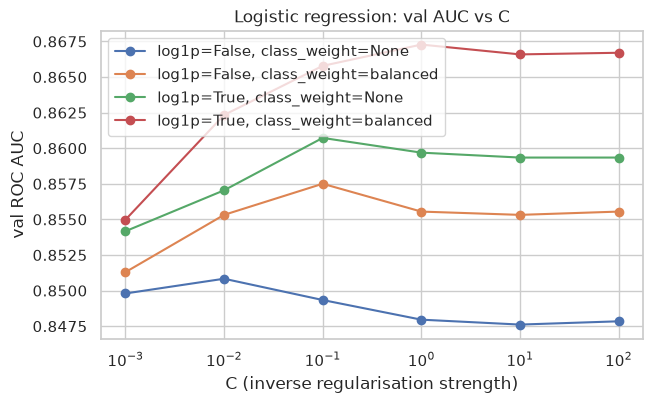

In [30]:
plt.figure(figsize=(7, 4))
for (log, cw), group in df_lr.groupby(['log1p', 'class_weight']):
    plt.plot(group.C, group.auc, marker='o', label=f'log1p={log}, class_weight={cw}')
plt.xscale('log')
plt.xlabel('C (inverse regularisation strength)')
plt.ylabel('val ROC AUC')
plt.title('Logistic regression: val AUC vs C')
plt.legend()
plt.show()

- **`log1p` helps:** for every setting it adds about 0.01 AUC.
- **`C` hardly matters** once it is ≥ 0.1. The curves are flat, so the model isn't overfitting.
- **`class_weight='balanced'`** gives another ~0.005–0.007 on validation. Before taking it, though, look at what it does to the output:

In [31]:
# Does class_weight='balanced' keep the output a probability? Compare the average prediction with the real share.
print(f'share of good wines in val: {y_val.mean():.3f}')
df_lr.groupby(['log1p', 'class_weight']).mean_pred.mean().round(3)

share of good wines in val: 0.136


log1p  class_weight
False  None            0.140
       balanced        0.371
True   None            0.138
       balanced        0.364
Name: mean_pred, dtype: float64

With `class_weight='balanced'` the average predicted "probability" is about **0.37**, while only 13.6% of wines are actually good. Re-weighting changes the *ranking* only a little, but it shifts every score upwards, so the outputs are no longer probabilities. Without weights the average prediction (0.138) matches reality.

Our API returns `good_probability`, so a QC technician should be able to read 0.6 as "about a 60% chance". That gain of under 0.01 AUC on a validation set with only 37 good wines is within noise, so it isn't worth giving up calibrated probabilities. **Choice: `log1p`, no class weights, and the `C` with the best validation AUC.**

In [32]:
lr_scores = df_lr[(df_lr.log1p == True) & (df_lr.class_weight == 'None')]
lr_C = lr_scores.loc[lr_scores.auc.idxmax(), 'C']
print('chosen C:', lr_C)

lr = make_lr(C=lr_C, log=True)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict_proba(X_val)[:, 1]
evaluate(y_val, y_pred_lr)

chosen C: 0.1


{'roc_auc': 0.8607245543415757, 'pr_auc': 0.45873219754243094}

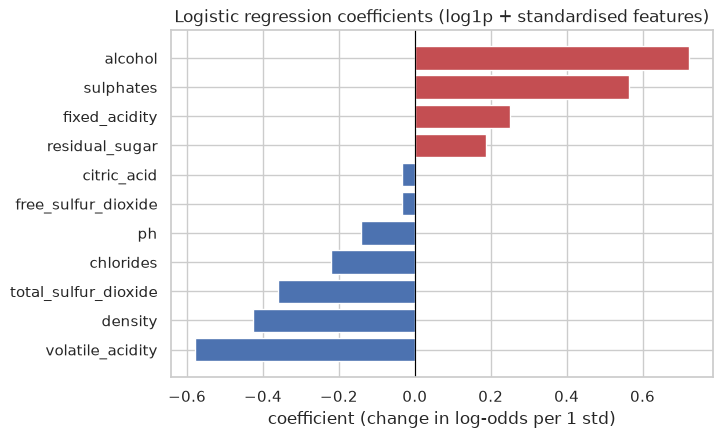

alcohol                 0.721
volatile_acidity       -0.578
sulphates               0.565
density                -0.426
total_sulfur_dioxide   -0.360
fixed_acidity           0.252
chlorides              -0.220
residual_sugar          0.188
ph                     -0.141
free_sulfur_dioxide    -0.035
citric_acid            -0.033
dtype: float64

In [33]:
coef = pd.Series(lr[-1].coef_[0], index=feature_names).sort_values()

plt.figure(figsize=(7, 4.5))
plt.barh(coef.index, coef.values, color=['#c44e52' if v > 0 else '#4c72b0' for v in coef.values])
plt.axvline(0, color='black', lw=0.8)
plt.title('Logistic regression coefficients (log1p + standardised features)')
plt.xlabel('coefficient (change in log-odds per 1 std)')
plt.show()
coef.sort_values(key=abs, ascending=False).round(3)

After `log1p` and scaling, each coefficient is the change in log-odds of "good" for a one-standard-deviation increase in that feature.
- **Raise the odds:** `alcohol` (+0.72) and `sulphates` (+0.57).
- **Lower them:** `volatile_acidity` (−0.58), `density` (−0.43) and `total_sulfur_dioxide` (−0.36).

`citric_acid` gets almost zero weight even though it ranked high in the EDA. It is correlated with `fixed_acidity` and (negatively) with `volatile_acidity`, so once those are in the model it adds little new information. This is the collinearity effect noted in §3.5.

> **Takeaway (§6).** Tuned LR: `log1p` + scaling, no class weights, `C=0.1`, val ROC AUC 0.861. That is below the untuned baseline's 0.872 on this one split, a first hint that the validation set is noisy. §10 checks both with cross-validation.

## 7. Decision tree

We tune `max_depth` (how many questions the tree may ask in a row) and `min_samples_leaf` (the smallest group a leaf may describe). Both limit overfitting.

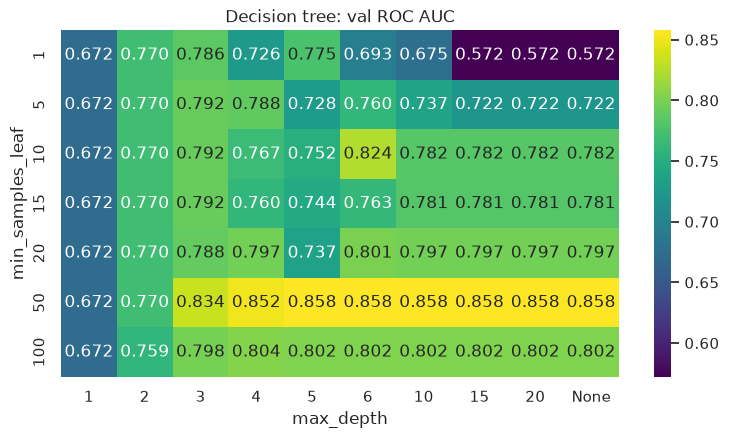

In [34]:
scores = []
for depth in [1, 2, 3, 4, 5, 6, 10, 15, 20, None]:
    for s in [1, 5, 10, 15, 20, 50, 100]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=s, random_state=1)
        dt.fit(X_train, y_train)
        y_pred = dt.predict_proba(X_val)[:, 1]
        scores.append((str(depth), s, roc_auc_score(y_val, y_pred)))

df_dt = pd.DataFrame(scores, columns=['max_depth', 'min_samples_leaf', 'auc'])
depth_order = ['1', '2', '3', '4', '5', '6', '10', '15', '20', 'None']
pivot = df_dt.pivot(index='min_samples_leaf', columns='max_depth', values='auc')[depth_order]

plt.figure(figsize=(9, 4.5))
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='viridis')
plt.title('Decision tree: val ROC AUC')
plt.show()

In [35]:
best = df_dt.loc[df_dt.auc.idxmax()]
dt_depth = None if best.max_depth == 'None' else int(best.max_depth)
dt_leaf = int(best.min_samples_leaf)
print(f'best: max_depth={dt_depth}, min_samples_leaf={dt_leaf}, val AUC={best.auc:.4f}')

dt = DecisionTreeClassifier(max_depth=dt_depth, min_samples_leaf=dt_leaf, random_state=1)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict_proba(X_val)[:, 1]
evaluate(y_val, y_pred_dt)

best: max_depth=5, min_samples_leaf=50, val AUC=0.8576


{'roc_auc': 0.8576193214491087, 'pr_auc': 0.47067622726186836}

In [36]:
# a shallow tree is easy to read: which splits does it make first?
small_tree = DecisionTreeClassifier(max_depth=2, random_state=1).fit(X_train, y_train)
print(export_text(small_tree, feature_names=feature_names, show_weights=True))

|--- alcohol <= 11.55
|   |--- volatile_acidity <= 0.38
|   |   |--- weights: [96.00, 30.00] class: 0
|   |--- volatile_acidity >  0.38
|   |   |--- weights: [539.00, 23.00] class: 0
|--- alcohol >  11.55
|   |--- sulphates <= 0.69
|   |   |--- weights: [50.00, 16.00] class: 0
|   |--- sulphates >  0.69
|   |   |--- weights: [20.00, 41.00] class: 1



The best tree has `max_depth=5` and `min_samples_leaf=50`: large leaves, i.e. heavy regularisation. Deep trees with small leaves memorise the training wines and score much worse on validation (top-right of the heatmap).

The depth-2 tree tells a story that matches the EDA. Among wines with **more than 11.55% alcohol and sulphates above 0.69**, 41 of 61 are good. In the low-alcohol, high-volatile-acidity group it's only 23 of 562.

> **Takeaway (§7).** A single tree reaches val AUC 0.858. It is easy to read, but its predictions jump in steps, and we'll see in §10 that it is the least stable model.

## 8. Random forest

A random forest averages many trees, each trained on a bootstrap sample with a random subset of features, which smooths out a single tree's instability. Following the course, we tune one parameter at a time and plot validation AUC against `n_estimators`:
1. `max_depth` ∈ {5, 10, 15};
2. `min_samples_leaf` ∈ {1, 3, 5, 10, 50} at the best depth;
3. `class_weight='balanced'` or not.

The single highest point on a curve is often a lucky spike. So we compare curves by their **average AUC for n_estimators ≥ 100**, where the forest has stabilised.

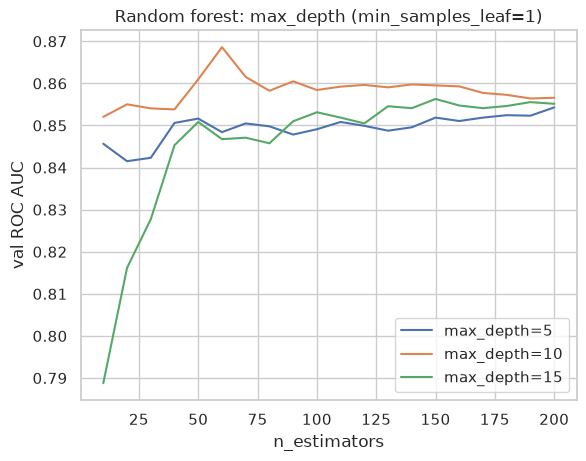

,mean_n>=100,max
5,0.8511,0.8543
10,0.8584,0.8686
15,0.8541,0.8563


In [37]:
n_values = range(10, 201, 10)

def rf_curve(max_depth, min_samples_leaf, class_weight=None):
    aucs = []
    for n in n_values:
        rf = RandomForestClassifier(n_estimators=n, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                    class_weight=class_weight, random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)
        aucs.append(roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1]))
    return aucs

rf_scores = {}
for d in [5, 10, 15]:
    rf_scores[d] = rf_curve(d, 1)
    plt.plot(n_values, rf_scores[d], label=f'max_depth={d}')
plt.xlabel('n_estimators'); plt.ylabel('val ROC AUC'); plt.title('Random forest: max_depth (min_samples_leaf=1)')
plt.legend(); plt.show()

# summarise each curve by its average over n_estimators >= 100 (more stable than the single best point)
summary = pd.DataFrame({d: [np.mean(a[9:]), np.max(a)] for d, a in rf_scores.items()}, index=['mean_n>=100', 'max']).T.round(4)
summary

chosen max_depth: 10


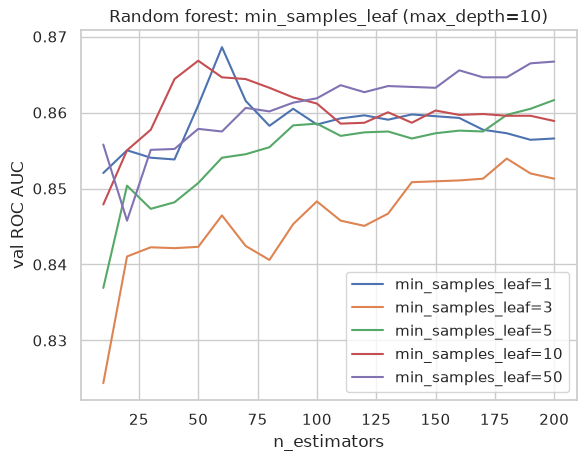

,mean_n>=100,max
1,0.8584,0.8686
3,0.8497,0.8539
5,0.8583,0.8616
10,0.8595,0.8668
50,0.8642,0.8667


In [38]:
rf_depth = int(summary['mean_n>=100'].idxmax())
print('chosen max_depth:', rf_depth)

rf_scores_leaf = {}
for s in [1, 3, 5, 10, 50]:
    rf_scores_leaf[s] = rf_curve(rf_depth, s)
    plt.plot(n_values, rf_scores_leaf[s], label=f'min_samples_leaf={s}')
plt.xlabel('n_estimators'); plt.ylabel('val ROC AUC'); plt.title(f'Random forest: min_samples_leaf (max_depth={rf_depth})')
plt.legend(); plt.show()

summary = pd.DataFrame({s: [np.mean(a[9:]), np.max(a)] for s, a in rf_scores_leaf.items()}, index=['mean_n>=100', 'max']).T.round(4)
summary

chosen min_samples_leaf: 50


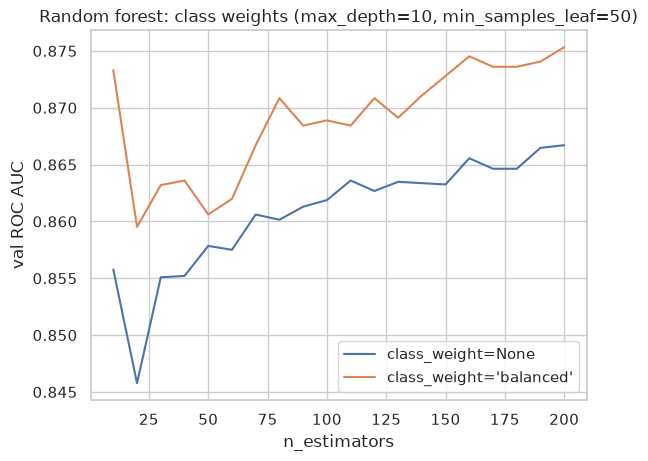

mean AUC n>=100: None=0.8642, balanced=0.8720


In [39]:
rf_leaf = int(summary['mean_n>=100'].idxmax())
print('chosen min_samples_leaf:', rf_leaf)

balanced = rf_curve(rf_depth, rf_leaf, class_weight='balanced')
plt.plot(n_values, rf_scores_leaf[rf_leaf], label='class_weight=None')
plt.plot(n_values, balanced, label="class_weight='balanced'")
plt.xlabel('n_estimators'); plt.ylabel('val ROC AUC'); plt.title(f'Random forest: class weights (max_depth={rf_depth}, min_samples_leaf={rf_leaf})')
plt.legend(); plt.show()
print(f"mean AUC n>=100: None={np.mean(rf_scores_leaf[rf_leaf][9:]):.4f}, balanced={np.mean(balanced[9:]):.4f}")

In [40]:
rf_n = 200
rf_class_weight = 'balanced' if np.mean(balanced[9:]) > np.mean(rf_scores_leaf[rf_leaf][9:]) else None
print(f'final RF: n_estimators={rf_n}, max_depth={rf_depth}, min_samples_leaf={rf_leaf}, class_weight={rf_class_weight}')

rf = RandomForestClassifier(n_estimators=rf_n, max_depth=rf_depth, min_samples_leaf=rf_leaf,
                            class_weight=rf_class_weight, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict_proba(X_val)[:, 1]
evaluate(y_val, y_pred_rf)

final RF: n_estimators=200, max_depth=10, min_samples_leaf=50, class_weight=balanced


{'roc_auc': 0.8753306497987348, 'pr_auc': 0.5523454863856325}

- `max_depth=10` is best on average.
- `min_samples_leaf=50` gives the highest and smoothest curve. As with the single tree, large leaves help on this small, noisy dataset.
- `class_weight='balanced'` adds ~0.008 average AUC. Random-forest scores aren't well-calibrated probabilities anyway, so we keep it for this candidate.

> **Takeaway (§8).** Final RF: 200 trees, `max_depth=10`, `min_samples_leaf=50`, balanced class weights. Val ROC AUC **0.875** and PR AUC **0.552**, the best of the models so far on this split.

## 9. XGBoost

Gradient boosting builds trees one after another, each correcting the errors of the previous ones. We use `xgb.train` with a watchlist, so XGBoost reports train and validation AUC after every 5 rounds. We capture that log with `%%capture` and parse it into a table (the course's `parse_xgb_output` pattern).

Tuning order: `eta` (learning rate) → `max_depth` → `min_child_weight` (minimum amount of data a leaf must hold) → `scale_pos_weight` (extra weight for the positive class).

In [41]:
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names)
watchlist = [(dtrain, 'train'), (dval, 'val')]

def parse_xgb_output(output):
    # turn lines like "[10]\ttrain-auc:0.95\tval-auc:0.86" into a DataFrame
    results = []
    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')
        results.append((int(it_line.strip('[]')),
                        float(train_line.split(':')[1]),
                        float(val_line.split(':')[1])))
    return pd.DataFrame(results, columns=['num_iter', 'train_auc', 'val_auc'])

def xgb_params(eta=0.3, max_depth=6, min_child_weight=1, scale_pos_weight=1):
    return {'eta': eta, 'max_depth': max_depth, 'min_child_weight': min_child_weight,
            'scale_pos_weight': scale_pos_weight, 'objective': 'binary:logistic',
            'eval_metric': 'auc', 'nthread': 8, 'seed': 1, 'verbosity': 1}

xgb_scores = {}

First, the default parameters (`eta=0.3`, `max_depth=6`, `min_child_weight=1`):

In [42]:
%%capture output
model = xgb.train(xgb_params(), dtrain, num_boost_round=200, evals=watchlist, verbose_eval=5)

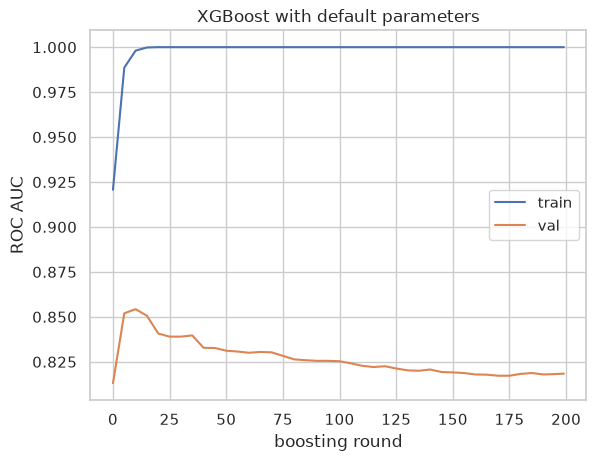

In [43]:
df_score = parse_xgb_output(output)
plt.plot(df_score.num_iter, df_score.train_auc, label='train')
plt.plot(df_score.num_iter, df_score.val_auc, label='val')
plt.xlabel('boosting round'); plt.ylabel('ROC AUC'); plt.title('XGBoost with default parameters')
plt.legend(); plt.show()

This is classic overfitting. Training AUC quickly reaches ~1.0 (the model memorises the training wines), while validation AUC peaks in the first few rounds and then drifts down. The tuning steps below are mostly about **holding the model back**.

In [44]:
%%capture output
for eta in [0.3, 0.1, 0.05, 0.01]:
    print(f'#eta={eta}')
    xgb.train(xgb_params(eta=eta), dtrain, num_boost_round=300, evals=watchlist, verbose_eval=5)

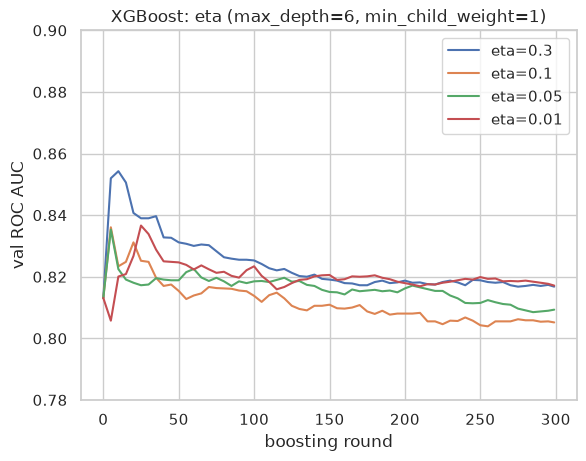

chosen eta: 0.3


,best_val_auc,at_round
setting,,
eta=0.3,0.8543,10
eta=0.1,0.8361,5
eta=0.05,0.8353,5
eta=0.01,0.8366,25


In [45]:
def parse_many(output):
    # split the captured log into one DataFrame per '#key' block
    blocks, key, lines = {}, None, []
    for line in output.stdout.strip().split('\n'):
        if line.startswith('#'):
            if key is not None:
                blocks[key] = lines
            key, lines = line[1:], []
        else:
            lines.append(line)
    blocks[key] = lines
    class O: pass
    res = {}
    for k, ls in blocks.items():
        o = O(); o.stdout = '\n'.join(ls)
        res[k] = parse_xgb_output(o)
    return res

def plot_and_summarise(results, title):
    rows = []
    for k, d in results.items():
        plt.plot(d.num_iter, d.val_auc, label=k)
        best = d.loc[d.val_auc.idxmax()]
        rows.append((k, best.val_auc, int(best.num_iter)))
    plt.xlabel('boosting round'); plt.ylabel('val ROC AUC'); plt.title(title)
    plt.ylim(0.78, 0.90); plt.legend(); plt.show()
    return pd.DataFrame(rows, columns=['setting', 'best_val_auc', 'at_round']).set_index('setting').round(4)

summary = plot_and_summarise(parse_many(output), 'XGBoost: eta (max_depth=6, min_child_weight=1)')
xgb_eta = float(summary.best_val_auc.idxmax().split('=')[1])
print('chosen eta:', xgb_eta)
summary

In [46]:
%%capture output
for d in [3, 4, 6, 10]:
    print(f'#max_depth={d}')
    xgb.train(xgb_params(eta=xgb_eta, max_depth=d), dtrain, num_boost_round=300, evals=watchlist, verbose_eval=5)

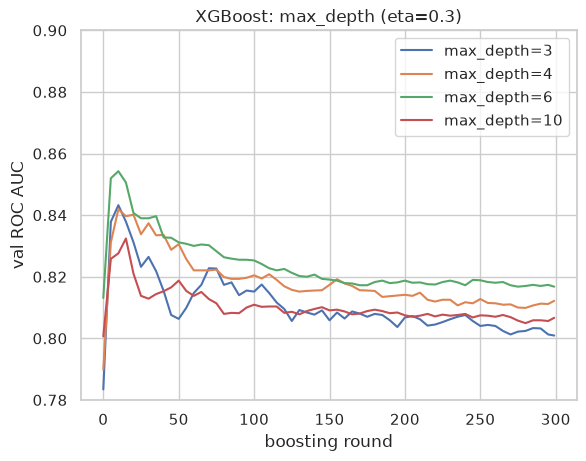

chosen max_depth: 6


,best_val_auc,at_round
setting,,
max_depth=3,0.8432,10
max_depth=4,0.8419,10
max_depth=6,0.8543,10
max_depth=10,0.8324,15


In [47]:
summary = plot_and_summarise(parse_many(output), f'XGBoost: max_depth (eta={xgb_eta})')
xgb_depth = int(summary.best_val_auc.idxmax().split('=')[1])
print('chosen max_depth:', xgb_depth)
summary

In [48]:
%%capture output
for w in [1, 10, 30]:
    print(f'#min_child_weight={w}')
    xgb.train(xgb_params(eta=xgb_eta, max_depth=xgb_depth, min_child_weight=w), dtrain,
              num_boost_round=300, evals=watchlist, verbose_eval=5)

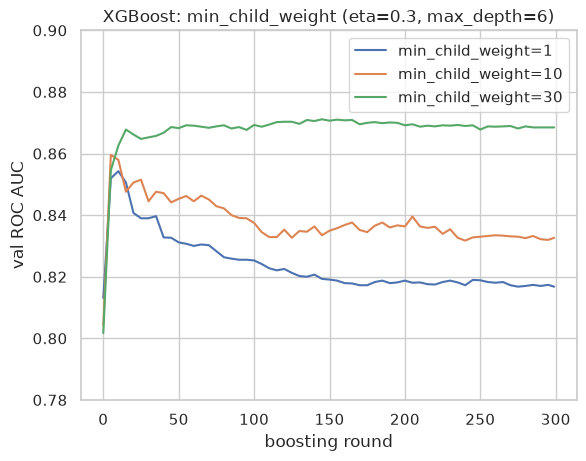

chosen min_child_weight: 30


,best_val_auc,at_round
setting,,
min_child_weight=1,0.8543,10
min_child_weight=10,0.8596,5
min_child_weight=30,0.8711,145


In [49]:
summary = plot_and_summarise(parse_many(output), f'XGBoost: min_child_weight (eta={xgb_eta}, max_depth={xgb_depth})')
xgb_mcw = int(summary.best_val_auc.idxmax().split('=')[1])
print('chosen min_child_weight:', xgb_mcw)
summary

`eta` and `max_depth` change the peak only slightly, and every curve peaks early and then decays. **`min_child_weight=30` is the step that matters.** It forces every leaf to cover a substantial group of wines, so the trees stay small and the validation curve stays high and flat instead of decaying (best 0.871).

Next, `scale_pos_weight` = neg/pos ≈ 6.4, the XGBoost equivalent of balanced class weights:

In [50]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
print(f'neg/pos ratio: {spw:.2f}')

neg/pos ratio: 6.41


In [51]:
%%capture output
for s in [1, spw]:
    print(f'#scale_pos_weight={s:.2f}')
    xgb.train(xgb_params(eta=xgb_eta, max_depth=xgb_depth, min_child_weight=xgb_mcw, scale_pos_weight=s),
              dtrain, num_boost_round=300, evals=watchlist, verbose_eval=5)

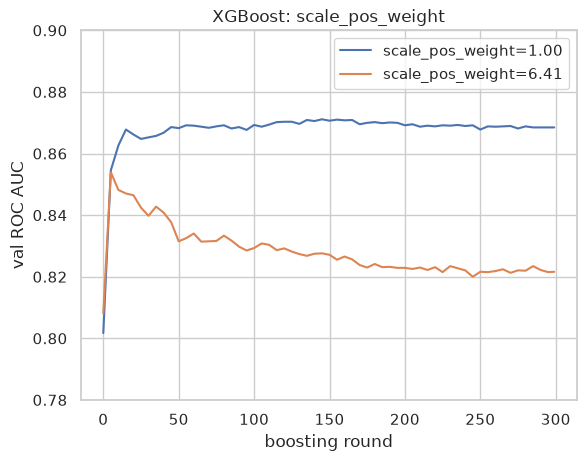

,best_val_auc,at_round
setting,,
scale_pos_weight=1.00,0.8711,145
scale_pos_weight=6.41,0.8539,5


In [52]:
summary = plot_and_summarise(parse_many(output), 'XGBoost: scale_pos_weight')
summary

In [53]:
%%capture output
xgb.train(xgb_params(eta=xgb_eta, max_depth=xgb_depth, min_child_weight=xgb_mcw), dtrain,
          num_boost_round=300, evals=watchlist, verbose_eval=5)

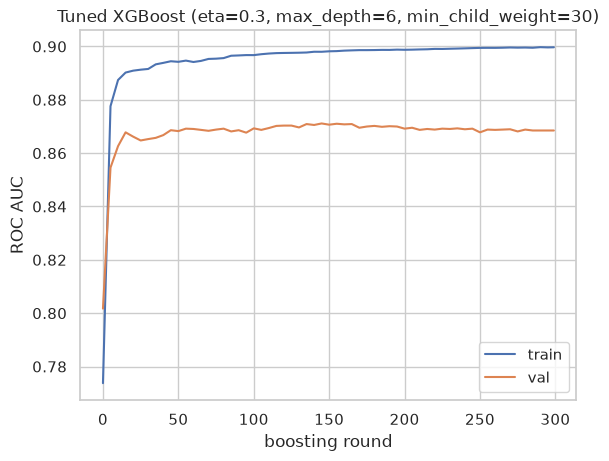

,train_auc,val_auc
num_iter,,
0,0.7738,0.8017
25,0.8913,0.8648
50,0.8942,0.8683
100,0.8968,0.8693
150,0.8982,0.8707
200,0.8988,0.8692
250,0.8995,0.8678
295,0.8996,0.8685


In [54]:
df_score = parse_xgb_output(output)
plt.plot(df_score.num_iter, df_score.train_auc, label='train')
plt.plot(df_score.num_iter, df_score.val_auc, label='val')
plt.xlabel('boosting round'); plt.ylabel('ROC AUC')
plt.title(f'Tuned XGBoost (eta={xgb_eta}, max_depth={xgb_depth}, min_child_weight={xgb_mcw})')
plt.legend(); plt.show()
df_score.set_index('num_iter').loc[[0, 25, 50, 100, 150, 200, 250, 295]].round(4)

`scale_pos_weight` makes things worse (best 0.854 vs 0.871), so we keep the default of 1.

With `min_child_weight=30`, the gap between train AUC (~0.90) and validation AUC (~0.87) is small: the model is no longer memorising. Validation AUC plateaus from about round 50 and peaks around round 150, so we take **150 rounds**.

For the comparison and the final pipeline we use `XGBClassifier`, the sklearn API. Parameter names translate as `eta` → `learning_rate` and `num_boost_round` → `n_estimators`.

In [55]:
xgb_rounds = 150

xgb_model = XGBClassifier(learning_rate=xgb_eta, max_depth=xgb_depth, min_child_weight=xgb_mcw,
                          n_estimators=xgb_rounds, random_state=1, n_jobs=8)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict_proba(X_val)[:, 1]
evaluate(y_val, y_pred_xgb)

{'roc_auc': 0.8709028177113284, 'pr_auc': 0.5329115084528713}

The sklearn-API model reproduces the `xgb.train` result (val AUC 0.871 at ~150 rounds), so the parameter translation is correct.

> **Takeaway (§9).** Final XGBoost: `eta=0.3`, `max_depth=6`, `min_child_weight=30`, 150 rounds. Val ROC AUC **0.871**, PR AUC **0.533**. Strong regularisation was the key, which again suggests the signal in this data is fairly simple.

## 10. Model comparison and feature importance

The validation set has only 272 wines, 37 of them good. Moving just one or two good wines up or down the ranking changes ROC AUC by about 0.01, which is as large as the differences between our models.

So we also run **5-fold stratified cross-validation on full_train** (1,087 wines, 147 good) for every tuned model. Every wine is used for validation once, and the spread across folds shows how much a score moves just because of the split. `DictVectorizer` is put inside the pipeline, so it is fitted inside each fold.

In [56]:
candidates = {
    'LR (default, reference)': LogisticRegression(max_iter=1000),
    'logistic regression': make_pipeline(FunctionTransformer(np.log1p), StandardScaler(),
                                         LogisticRegression(C=lr_C, max_iter=1000)),
    'decision tree': DecisionTreeClassifier(max_depth=dt_depth, min_samples_leaf=dt_leaf, random_state=1),
    'random forest': RandomForestClassifier(n_estimators=rf_n, max_depth=rf_depth, min_samples_leaf=rf_leaf,
                                            class_weight=rf_class_weight, random_state=1, n_jobs=-1),
    'xgboost': XGBClassifier(learning_rate=xgb_eta, max_depth=xgb_depth, min_child_weight=xgb_mcw,
                             n_estimators=xgb_rounds, random_state=1, n_jobs=8),
}
params = {
    'LR (default, reference)': 'no scaling, C=1',
    'logistic regression': f'log1p + scaling, C={lr_C}',
    'decision tree': f'max_depth={dt_depth}, min_samples_leaf={dt_leaf}',
    'random forest': f'n_estimators={rf_n}, max_depth={rf_depth}, min_samples_leaf={rf_leaf}, class_weight={rf_class_weight}',
    'xgboost': f'eta={xgb_eta}, max_depth={xgb_depth}, min_child_weight={xgb_mcw}, rounds={xgb_rounds}',
}

dicts_full_train = df_full_train.to_dict(orient='records')
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

rows = []
for name, model in candidates.items():
    # validation (fit on train)
    model.fit(X_train, y_train)
    val = evaluate(y_val, model.predict_proba(X_val)[:, 1])
    # 5-fold CV on full_train; DictVectorizer is inside the pipeline so it is fitted per fold
    cv_aucs, cv_aps = [], []
    for tr_idx, va_idx in cv.split(dicts_full_train, y_full_train):
        pipe = make_pipeline(DictVectorizer(sparse=False), model)
        pipe.fit([dicts_full_train[i] for i in tr_idx], y_full_train[tr_idx])
        y_pred = pipe.predict_proba([dicts_full_train[i] for i in va_idx])[:, 1]
        cv_aucs.append(roc_auc_score(y_full_train[va_idx], y_pred))
        cv_aps.append(average_precision_score(y_full_train[va_idx], y_pred))
    rows.append((name, params[name], val['roc_auc'], val['pr_auc'], np.mean(cv_aucs), np.std(cv_aucs), np.mean(cv_aps), np.std(cv_aps)))

df_compare = pd.DataFrame(rows, columns=['model', 'params', 'val_roc_auc', 'val_pr_auc', 'cv_roc_auc_mean', 'cv_roc_auc_std', 'cv_pr_auc_mean', 'cv_pr_auc_std'])
df_compare.drop(columns='params').round(4)

,model,val_roc_auc,val_pr_auc,cv_roc_auc_mean,cv_roc_auc_std,cv_pr_auc_mean,cv_pr_auc_std
0,"LR (default, reference)",0.8723,0.4687,0.8597,0.0329,0.5024,0.0595
1,logistic regression,0.8607,0.4587,0.8727,0.0202,0.5427,0.0417
2,decision tree,0.8576,0.4707,0.8286,0.0362,0.4490,0.0547
3,random forest,0.8753,0.5523,0.8656,0.0199,0.5560,0.0776
4,xgboost,0.8709,0.5329,0.8596,0.0291,0.5439,0.0918


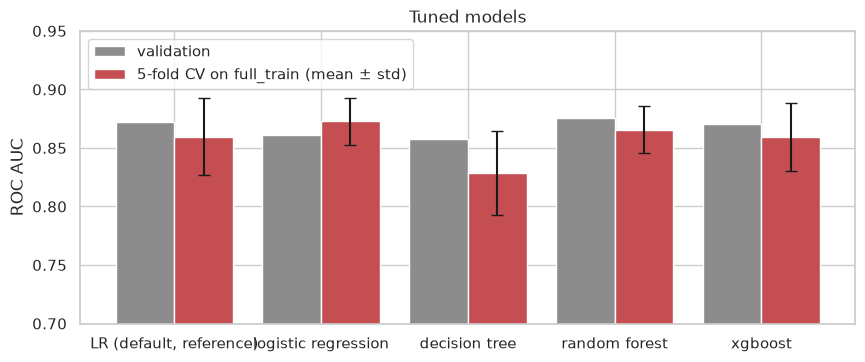

In [57]:
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(df_compare))
ax.bar(x - 0.2, df_compare.val_roc_auc, width=0.4, label='validation', color='#8c8c8c')
ax.bar(x + 0.2, df_compare.cv_roc_auc_mean, width=0.4, yerr=df_compare.cv_roc_auc_std, capsize=4,
       label='5-fold CV on full_train (mean ± std)', color='#c44e52')
ax.set_xticks(x, df_compare.model)
ax.set_ylim(0.7, 0.95); ax.set_ylabel('ROC AUC'); ax.set_title('Tuned models')
ax.legend(loc='upper left')
save('model_comparison')
plt.show()

**What the table says:**
- **Decision tree:** clearly the weakest and least stable (CV 0.829 ± 0.036).
- **Logistic regression, random forest, XGBoost:** they **cannot be separated**. On the single validation split RF leads (0.875 vs 0.871 vs 0.861). In cross-validation the order flips: LR 0.873, RF 0.866, XGB 0.860, each with a fold-to-fold std of 0.02–0.03. CV PR AUC is also a tie (0.54–0.56, std 0.04–0.09). The spec says CV is there to confirm that the validation ranking isn't split luck; here it does **not** confirm it.
- **Untuned LR (reference row):** high on validation, but lower in CV than the tuned LR. That confirms its validation score was partly luck.

**Selection.** The rule is to pick the best model and, when scores are within noise, prefer the simpler one. Here the three are tied within noise, and logistic regression:
- has the best cross-validated ROC AUC, which uses 4× more validation data than the single split;
- is the **simplest** model (12 numbers: 11 coefficients plus an intercept);
- outputs **calibrated probabilities** (§6), which the API promises. The balanced RF does not.
- is easy to explain to a QC lab: "more alcohol and sulphates raise the chance; volatile acidity lowers it".

**→ Final model: logistic regression (`log1p` + scaling, `C=0.1`).**

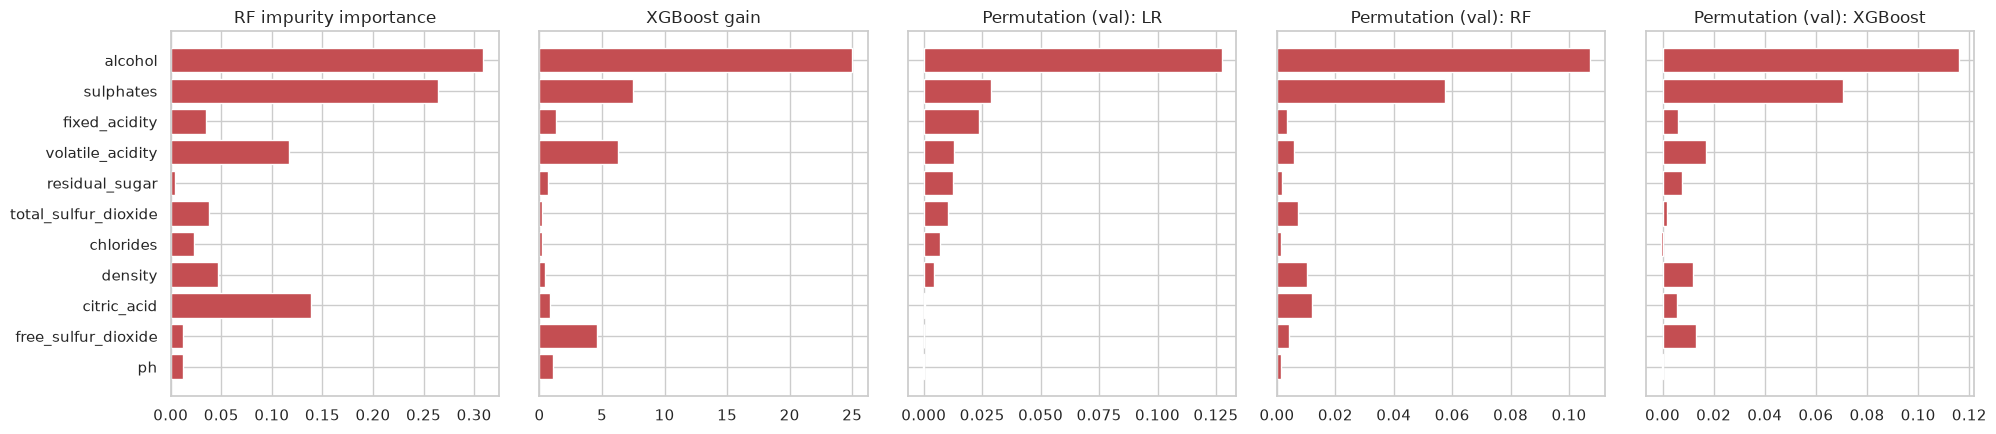

In [58]:
rf_imp = pd.Series(candidates['random forest'].feature_importances_, index=feature_names)
gain = candidates['xgboost'].get_booster().get_score(importance_type='gain')
# the model was trained on a numpy array, so XGBoost calls the features f0, f1, ... -> map back to names
xgb_imp = pd.Series({feature_names[int(k[1:])]: v for k, v in gain.items()}).reindex(feature_names).fillna(0)

perm = {}
for name in ['logistic regression', 'random forest', 'xgboost']:
    r = permutation_importance(candidates[name], X_val, y_val, scoring='roc_auc', n_repeats=20, random_state=1)
    perm[name] = pd.Series(r.importances_mean, index=feature_names)

fig, axes = plt.subplots(1, 5, figsize=(20, 4.5), sharey=True)
order = perm['logistic regression'].sort_values().index
panels = [(rf_imp, 'RF impurity importance'), (xgb_imp, 'XGBoost gain'),
          (perm['logistic regression'], 'Permutation (val): LR'), (perm['random forest'], 'Permutation (val): RF'),
          (perm['xgboost'], 'Permutation (val): XGBoost')]
for ax, (s, title) in zip(axes, panels):
    ax.barh(order, s[order].values, color='#c44e52')
    ax.set_title(title)
plt.tight_layout()
save('feature_importance')
plt.show()

In [59]:
ranks = pd.DataFrame({
    'corr_with_good (EDA)': df_full_train.assign(good=y_full_train).corr()['good'].drop('good').abs(),
    'mutual_info (EDA)': mi,
    'RF impurity': rf_imp,
    'XGB gain': xgb_imp,
    'perm LR': perm['logistic regression'],
    'perm RF': perm['random forest'],
    'perm XGB': perm['xgboost'],
}).rank(ascending=False).astype(int)
ranks.sort_values('perm LR')

,corr_with_good (EDA),mutual_info (EDA),RF impurity,XGB gain,perm LR,perm RF,perm XGB
alcohol,1,1,1,1,1,1,1
sulphates,3,3,2,2,2,2,2
fixed_acidity,7,6,7,5,3,8,7
volatile_acidity,2,4,4,3,4,6,3
residual_sugar,11,10,11,8,5,9,6
total_sulfur_dioxide,6,8,6,11,6,5,9
chlorides,9,7,8,10,7,11,11
density,5,5,5,9,8,4,5
citric_acid,4,2,3,7,9,3,8
free_sulfur_dioxide,8,9,10,4,10,7,4


Three views of importance:
- **RF impurity importance:** how much the trees' splits on a feature reduce impurity.
- **XGBoost gain:** the average improvement in loss from splits on that feature.
- **Permutation importance on validation:** how much val AUC drops when one feature's values are shuffled. This is the only method that works the same way for all three models.

**Agreement:** in every method and every model, **alcohol is #1 and sulphates #2**. That matches the EDA, where alcohol ranked #1 by both correlation and mutual information, and sulphates #3. Volatile acidity is in the top 4 for most methods.

**Differences:**
- `citric_acid` is important for the trees (RF impurity #3) but not for LR (#9), because LR gets the same information from the correlated acidity features (§6).
- Low-signal features (pH, chlorides, residual sugar) stay at the bottom almost everywhere, as mutual information predicted.

> **Takeaway (§10).** LR, RF and XGBoost perform the same within noise (CV ROC AUC 0.86–0.87). We pick logistic regression: the best CV score, the simplest model and calibrated probabilities. Every method agrees that alcohol and sulphates drive the predictions.

## 11. Threshold selection

The model outputs a probability, and the API also has to give a yes/no answer. The threshold sets the trade-off between the two kinds of error:
- **false "good"** (low precision): a mediocre batch goes to the tasting panel or premium line. That wastes panel time, and it is a reputational risk if the batch is sold as premium without tasting;
- **missed "good"** (low recall): a good batch goes to the standard line and the winery loses premium revenue.

We pick the threshold on **validation** (model fitted on train), never on test. Following the spec, the default choice is the **F1-optimal** threshold, which balances precision and recall.

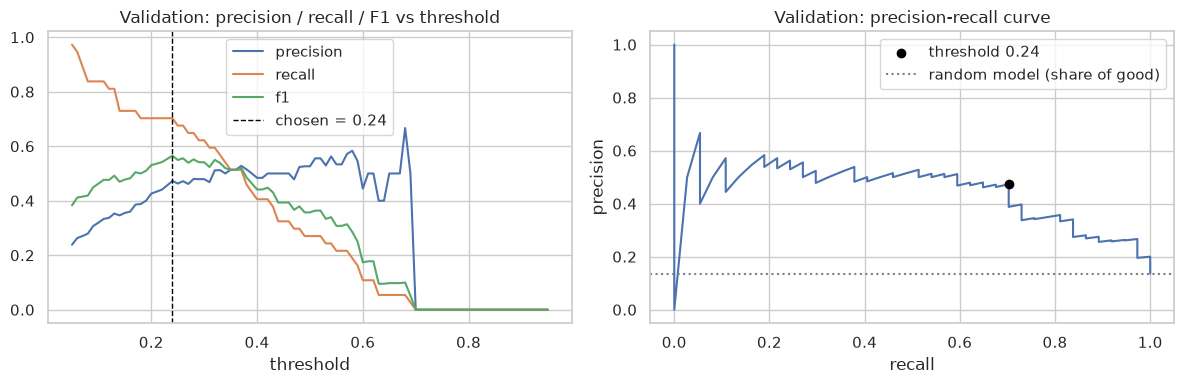

F1-optimal threshold: 0.24


,threshold,precision,recall,f1
15,0.20,0.426,0.703,0.531
19,0.24,0.473,0.703,0.565
25,0.30,0.479,0.622,0.541
35,0.40,0.484,0.405,0.441
45,0.50,0.526,0.270,0.357
55,0.60,0.444,0.108,0.174


In [60]:
final_name = 'logistic regression'
model = candidates[final_name].fit(X_train, y_train)
y_pred_val = model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.05, 0.96, 0.01)
rows = []
for t in thresholds:
    pred = y_pred_val >= t
    rows.append((t, precision_score(y_val, pred, zero_division=0), recall_score(y_val, pred), f1_score(y_val, pred)))
df_thr = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall', 'f1'])

best_thr = df_thr.loc[df_thr.f1.idxmax()]
threshold = round(float(best_thr.threshold), 2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for col in ['precision', 'recall', 'f1']:
    axes[0].plot(df_thr.threshold, df_thr[col], label=col)
axes[0].axvline(threshold, color='black', ls='--', lw=1, label=f'chosen = {threshold}')
axes[0].set_xlabel('threshold'); axes[0].set_title('Validation: precision / recall / F1 vs threshold'); axes[0].legend()

p, r, _ = precision_recall_curve(y_val, y_pred_val)
axes[1].plot(r, p)
axes[1].scatter([best_thr.recall], [best_thr.precision], color='black', zorder=3, label=f'threshold {threshold}')
axes[1].axhline(y_val.mean(), color='gray', ls=':', label='random model (share of good)')
axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision'); axes[1].set_title('Validation: precision-recall curve')
axes[1].legend()
plt.tight_layout()
save('threshold_selection')
plt.show()

print(f'F1-optimal threshold: {threshold}')
df_thr[df_thr.threshold.round(2).isin([0.2, 0.3, threshold, 0.4, 0.5, 0.6])].round(3)

The F1-optimal threshold is **0.24**. At that threshold the model finds about 70% of good wines (recall 0.70), and about 47% of the wines it flags are actually good (precision 0.47). That is 3.5× better than picking batches at random (13.6%).

It is well below 0.5 because good wines are rare. A batch with a 24% chance of being good is already about twice as likely to be good as an average batch.

**Business view.** In the main use case, prioritising batches for the tasting panel, the panel still tastes every flagged batch. A false "good" therefore costs one extra tasting, and a missed good batch costs premium revenue, so a recall-leaning threshold like 0.24 fits. If the flag were ever used to route wine to the premium line **without** tasting, precision would matter more and the threshold should go up. At 0.5, validation precision is 0.53 but recall drops to 0.27. The threshold is a stored constant in `model.bin`, so it can be changed without retraining.

> **Takeaway (§11).** Threshold = 0.24 (F1-optimal on validation): recall ≈ 0.70, precision ≈ 0.47.

## 12. Final model and test evaluation

We retrain the chosen pipeline on **full_train** (train + validation, 1,087 wines) and evaluate it **once** on the held-out test set. The pipeline is exactly the one `train.py` will save:

`DictVectorizer → log1p → StandardScaler → LogisticRegression(C=0.1)`

In [61]:
final_pipeline = make_pipeline(
    DictVectorizer(sparse=False),
    FunctionTransformer(np.log1p),
    StandardScaler(),
    LogisticRegression(C=lr_C, max_iter=1000),
)
final_pipeline.fit(df_full_train.to_dict(orient='records'), y_full_train)

y_pred_test = final_pipeline.predict_proba(df_test.to_dict(orient='records'))[:, 1]
test = evaluate(y_test, y_pred_test)
val_final = df_compare.set_index('model').loc[final_name]

pd.DataFrame({
    'validation (fit on train)': [val_final.val_roc_auc, val_final.val_pr_auc],
    'test (fit on full_train)': [test['roc_auc'], test['pr_auc']],
}, index=['ROC AUC', 'PR AUC']).round(4)

,validation (fit on train),test (fit on full_train)
ROC AUC,0.8607,0.8948
PR AUC,0.4587,0.5109


In [62]:
pred_test = y_pred_test >= threshold
print(f'threshold: {threshold}')
print(f'precision: {precision_score(y_test, pred_test):.3f}')
print(f'recall:    {recall_score(y_test, pred_test):.3f}')
print(f'F1:        {f1_score(y_test, pred_test):.3f}')
print(f'accuracy:  {accuracy_score(y_test, pred_test):.3f}   (always "not good" would get {1 - y_test.mean():.3f})')

threshold: 0.24
precision: 0.444
recall:    0.757
F1:        0.560
accuracy:  0.838   (always "not good" would get 0.864)


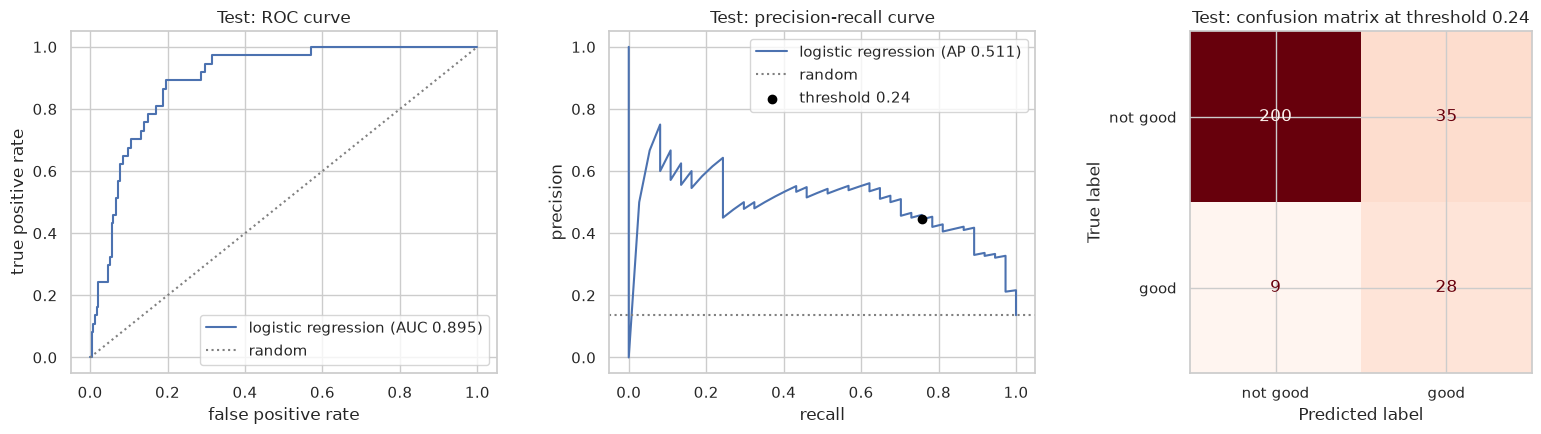

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

fpr, tpr, _ = roc_curve(y_test, y_pred_test)
axes[0].plot(fpr, tpr, label=f"logistic regression (AUC {test['roc_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], color='gray', ls=':', label='random')
axes[0].set_xlabel('false positive rate'); axes[0].set_ylabel('true positive rate'); axes[0].set_title('Test: ROC curve')
axes[0].legend()

p, r, _ = precision_recall_curve(y_test, y_pred_test)
axes[1].plot(r, p, label=f"logistic regression (AP {test['pr_auc']:.3f})")
axes[1].axhline(y_test.mean(), color='gray', ls=':', label='random')
axes[1].scatter([recall_score(y_test, pred_test)], [precision_score(y_test, pred_test)], color='black', zorder=3,
                label=f'threshold {threshold}')
axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision'); axes[1].set_title('Test: precision-recall curve')
axes[1].legend()

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=['not good', 'good']).plot(
    ax=axes[2], cmap='Reds', colorbar=False)
axes[2].set_title(f'Test: confusion matrix at threshold {threshold}')

plt.tight_layout()
save('test_evaluation')
plt.show()

In [64]:
# sanity check on the two example payloads used by the API 
examples = [
    {'fixed_acidity': 7.9, 'volatile_acidity': 0.35, 'citric_acid': 0.46, 'residual_sugar': 3.6,
     'chlorides': 0.078, 'free_sulfur_dioxide': 15.0, 'total_sulfur_dioxide': 37.0,
     'density': 0.9973, 'ph': 3.35, 'sulphates': 0.86, 'alcohol': 12.8},   # quality 8 in the data
    {'fixed_acidity': 7.4, 'volatile_acidity': 0.70, 'citric_acid': 0.0, 'residual_sugar': 1.9,
     'chlorides': 0.076, 'free_sulfur_dioxide': 11.0, 'total_sulfur_dioxide': 34.0,
     'density': 0.9978, 'ph': 3.51, 'sulphates': 0.56, 'alcohol': 9.4},    # quality 5 in the data
]
final_pipeline.predict_proba(examples)[:, 1].round(3)

array([0.61 , 0.009])

**Test results:** ROC AUC **0.895**, PR AUC **0.511**. At threshold 0.24:
- precision **0.44**, recall **0.76** (28 of the 37 good wines found), F1 **0.56**.
- In the confusion matrix, 35 not-good wines are flagged (false "good") and 9 good wines are missed.

**Test vs validation.** Test ROC AUC (0.895) is *higher* than validation (0.861). That is not a sign of a problem:
- the final model was trained on more data (1,087 vs 815 wines);
- with 37 good wines in each set, scores move by ±0.02–0.03 between splits. The CV spread in §10 was 0.02.

The test score is within that range above the CV mean (0.873), and test precision and recall are close to their validation values (0.47 / 0.70). **No sign of overfitting.**

**Accuracy, one last time.** On test the model's accuracy (0.838) is *lower* than "always not good" (0.864). Yet it finds 76% of the good wines instead of none, which is exactly why accuracy is the wrong metric here.

The two example wines from the spec behave as expected: the quality-8 wine gets **0.61** and the quality-5 wine **0.009**.

## 13. Summary

| | |
|---|---|
| **Data** | 1,599 red Vinho Verde wines → 1,359 after removing 240 exact duplicates (removed *before* splitting to avoid leakage) |
| **Target** | `good = quality ≥ 7` (13.5% positive) |
| **Split** | stratified 60/20/20 train/val/test, `random_state=1` |
| **Models tried** | logistic regression, decision tree, random forest, XGBoost, each tuned on validation and checked with 5-fold CV |
| **Final model** | `DictVectorizer → log1p → StandardScaler → LogisticRegression(C=0.1)`, trained on full_train |
| **Why this model** | LR, RF and XGBoost tie within noise (CV ROC AUC 0.86–0.87); LR has the best CV score, is the simplest and gives calibrated probabilities |
| **Threshold** | 0.24 (F1-optimal on validation) |
| **Test metrics** | ROC AUC 0.895 · PR AUC 0.511 · precision 0.44 · recall 0.76 · F1 0.56 |
| **Top features** | alcohol (+), sulphates (+), volatile acidity (−); density and total SO₂ (−) in LR |

**Lessons:**
- Duplicates inflated cross-validated AUC by ~0.045.
- Accuracy is useless at 13.5% positives.
- With small validation sets, cross-validation is needed before trusting a ranking.
- On this data, heavy regularisation (big leaves, `min_child_weight=30`) mattered more than model complexity.

**Limitations:**
- Only Portuguese red Vinho Verde from around 2009.
- No grape variety, producer or price information.
- The target is a subjective panel score.
- Very few wines at the extremes (quality 3 and 8).
- Test metrics rest on only 37 good wines, so treat them as roughly ±0.03.

**Next steps:**
- Add white wines (with a `wine_type` feature).
- Model the full quality score (regression or ordinal).
- Monitor live predictions against the panel's actual grades.